# 27 October 2026: PPS → DAC_A delay and jitter (RF-clock, board 8873292600AB)

**What was measured.** The time from the PPS rising edge to the start of the board's transmit burst on DAC_A, once per second for 10 minutes, on the Teledyne LeCroy HDO9404-MS (4 GHz, 20 GS/s, 50 ps per point).

**Board side** (RF-clock 1.3.0.8, M2 check in scope mode): one burst per PPS, starting on the PPS tick (`--offset-ticks 0`). The DAC mixer is bypassed and the burst is a 25 MHz square wave in I, so the first edge marks the burst start and does not depend on any carrier phase.
```
python -m rf_clock.checks.m2_tx_timing 700 --waveform square --scope-nco 0 --amplitude 32000 --offset-ticks 0
```
Digital result: 700/700 bursts, `TX_ACTUAL − PPS tick = 0` for every burst, no faults, MTS latencies DAC 1896 / ADC 1296.

**Scope side** (`rf_clock_board/experiments/scope_delay_capture.py`, on RF-clock-PC over USB): single trigger on C1, download C1 and C3, re-arm, for 600 s.
```
.venv/bin/python scope_delay_capture.py --seconds 600
```

**Wiring.**

| Signal | Connection |
|---|---|
| 10 MHz | FS725 → board external reference (direct); FS725 → EPG1 REF IN |
| PPS to the board | FS725 1PPS → EPG1 TRIG IN (threshold 1.30 V) → **output 2** (delay 7.48 ns actual) → J7 |
| PPS to the scope | EPG1 **output 4** (delay 0.52 ns actual) → **C1** |
| DAC_A | → **C3** (no loopback cable, no filter) |

**How each delay is measured.** PPS edge: the C1 crossing of 50 % between its low and high levels. Burst start: the first crossing of half the burst amplitude on C3 after the PPS edge (the first step is 0 → −A: DAC_A is inverted relative to I). Both are interpolated linearly between samples. Delay = burst start − PPS edge.

In [1]:
%matplotlib inline
import csv, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Image, display

Defining my usual plot appearance settings

In [2]:
plt.rcParams['font.size'] = '20';plt.rcParams['font.style'] = 'normal'
plt.rcParams['font.weight'] = 'normal';plt.rcParams['axes.grid'] = True;plt.rcParams['grid.linestyle'] = '-';
plt.rcParams['grid.linewidth'] = 0.4;plt.rcParams['grid.color'] = "Black";plt.rcParams['grid.alpha'] = 1;
plt.rcParams['lines.linewidth'] = 3;#plt.rcParams['axes.autolimit_mode'] = 'round_numbers';plt.rcParams['axes.axisbelow'] = True
plt.rcParams['xtick.direction'] = 'in';plt.rcParams['ytick.direction'] = 'in';plt.rcParams['xtick.major.width'] = 1
plt.rcParams['xtick.minor.width'] = 0.5;plt.rcParams['ytick.major.width'] = 1;plt.rcParams['ytick.minor.width'] = 0.5;
plt.rcParams['xtick.major.size'] = 4;plt.rcParams['xtick.minor.size'] = 2;plt.rcParams['ytick.major.size'] = 4;
plt.rcParams['ytick.minor.size'] = 2; plt.rcParams['svg.fonttype'] = 'none'; #cs = list(mcolors.TABLEAU_COLORS.values())
plt.rcParams['axes.linewidth']=1;plt.rcParams['xtick.top'] = True;plt.rcParams['ytick.right'] = True;
plt.rcParams['axes.spines.top'] = True;plt.rcParams['axes.spines.bottom'] = True;plt.rcParams['axes.spines.left'] = True;
plt.rcParams['axes.spines.right'] = True# Plot Appearance Settings

Additions for this report: a thicker frame and ticks, minor ticks on, and a lighter minor grid under the major one (`grids(ax)` is applied to every plot).

In [3]:
plt.rcParams['axes.linewidth'] = 2
plt.rcParams['xtick.major.width'] = 1.5;plt.rcParams['ytick.major.width'] = 1.5
plt.rcParams['xtick.minor.width'] = 1;plt.rcParams['ytick.minor.width'] = 1
plt.rcParams['xtick.major.size'] = 7;plt.rcParams['ytick.major.size'] = 7
plt.rcParams['xtick.minor.size'] = 3.5;plt.rcParams['ytick.minor.size'] = 3.5
plt.rcParams['xtick.minor.visible'] = True;plt.rcParams['ytick.minor.visible'] = True
plt.rcParams['axes.axisbelow'] = True

def grids(ax):
    ax.grid(which='major', color='Black', linewidth=0.6, alpha=1)
    ax.grid(which='minor', color='Black', linewidth=0.3, alpha=0.35)

## 1. Load the 10-minute run

In [4]:
RUN = Path("rf_clock_board/scope/scope_delay_20261027_163100")
SHORT = Path("rf_clock_board/scope/scope_delay_20261027_162017")   # the 2-minute run earlier the same day

def load(run):
    rows = list(csv.DictReader(open(run / "delays.csv")))
    col = lambda k: np.array([float(r[k]) for r in rows])
    return {"delay_ns": col("delay_s") * 1e9, "t_pps_ps": col("t_pps_s") * 1e12,
            "t_burst_ps": col("t_burst_s") * 1e12, "wall": col("wall_time")}

r = load(RUN)
d = r["delay_ns"]
t_s = r["wall"] - r["wall"][0]
summary = json.load(open(RUN / "summary.json"))
print(f"{d.size} acquisitions over {t_s[-1]:.0f} s, gaps > 1.5 s: {np.sum(np.diff(t_s) > 1.5)}")
print(f"scope: {summary['idn']}, {summary['points']} points per channel, {summary['sample_interval_s'] * 1e12:.0f} ps per point")

601 acquisitions over 600 s, gaps > 1.5 s: 0
scope: LECROY,HDO9404-MS,LCRY4404N30414,8.5.1, 10002 points per channel, 50 ps per point


## 2. Statistics

In [5]:
mean, sd = d.mean(), d.std(ddof=1)
dev_ps = (d - mean) * 1e3
pct = np.percentile(dev_ps, [0.5, 2.5, 16, 50, 84, 97.5, 99.5])
print(f"mean               {mean:.4f} ns")
print(f"standard deviation {sd * 1e3:.1f} ps")
print(f"min / max          {d.min():.4f} / {d.max():.4f} ns  (range {np.ptp(d) * 1e3:.0f} ps)")
print(f"16-84 % half-width {(pct[4] - pct[2]) / 2:.1f} ps   (equals the sdev for a Gaussian)")
print(f"skewness {stats.skew(d):+.3f}, excess kurtosis {stats.kurtosis(d):+.3f}, "
      f"Shapiro-Wilk p = {stats.shapiro(d).pvalue:.2f}")

mean               174.9337 ns
standard deviation 31.3 ps
min / max          174.8242 / 175.0248 ns  (range 201 ps)
16-84 % half-width 30.9 ps   (equals the sdev for a Gaussian)
skewness -0.149, excess kurtosis -0.037, Shapiro-Wilk p = 0.57


## 3. Histogram

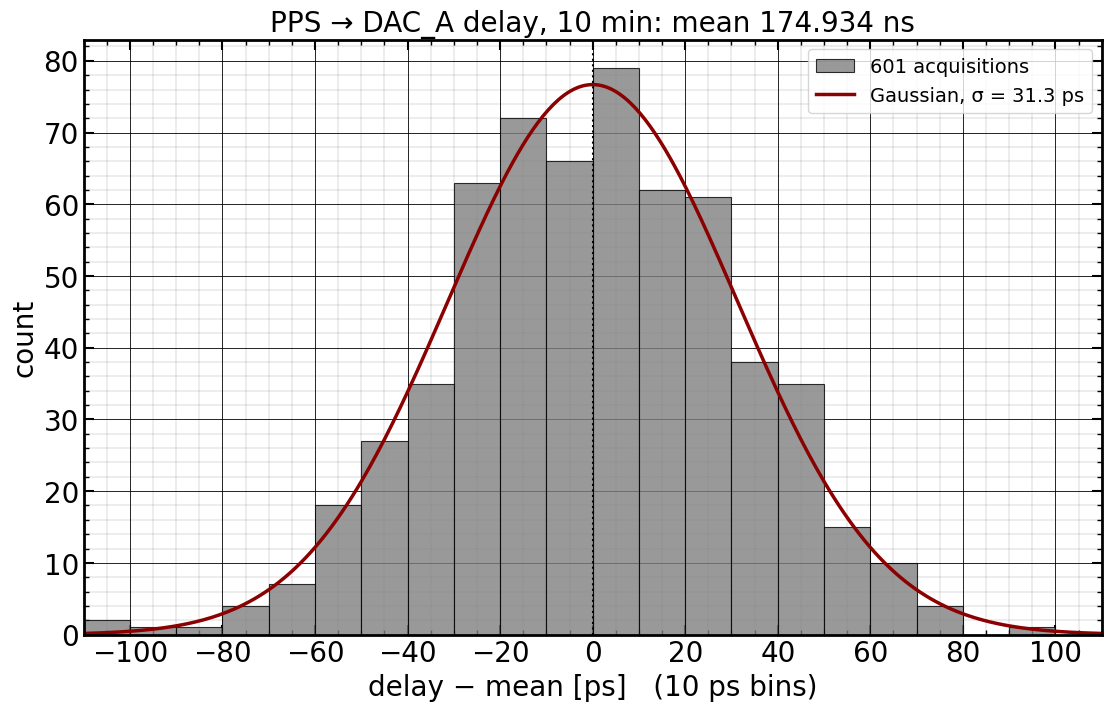

In [6]:
BIN_PS = 10
bins = np.arange(-110, 110 + BIN_PS, BIN_PS)       # equal 10-ps bins, symmetric about the mean
x = np.linspace(bins[0], bins[-1], 400)
gauss = d.size * (bins[1] - bins[0]) * stats.norm.pdf(x, 0, sd * 1e3)

fig, ax = plt.subplots(1, 1, figsize=(11, 7), layout='constrained')
ax.hist(dev_ps, bins=bins, color="grey", edgecolor="k", lw=0.8, alpha=0.8, label=f"{d.size} acquisitions")
ax.plot(x, gauss, "-", color="darkred", lw=2.5, label=f"Gaussian, σ = {sd * 1e3:.1f} ps")
ax.axvline(0, color="k", ls=":", lw=1.5)
ax.set_xlim(bins[0], bins[-1])
ax.set_xticks(np.arange(-100, 101, 20))
ax.set_xlabel(f"delay − mean [ps]   ({BIN_PS} ps bins)")
ax.set_ylabel("count")
ax.set_title(f"PPS → DAC_A delay, 10 min: mean {mean:.3f} ns", fontsize=20)
ax.legend(fontsize=14, loc="upper right")
grids(ax)
fig.savefig(RUN / "histogram.png", dpi=150)
plt.show()

## 4. Over time: is it white noise or does it drift?

Top: every acquisition, with a 60-s running mean. Bottom: the standard deviation of the mean of N consecutive acquisitions. For pure white noise it falls as $1/\sqrt{N}$ (dashed line); where it stops falling, slow variations take over.

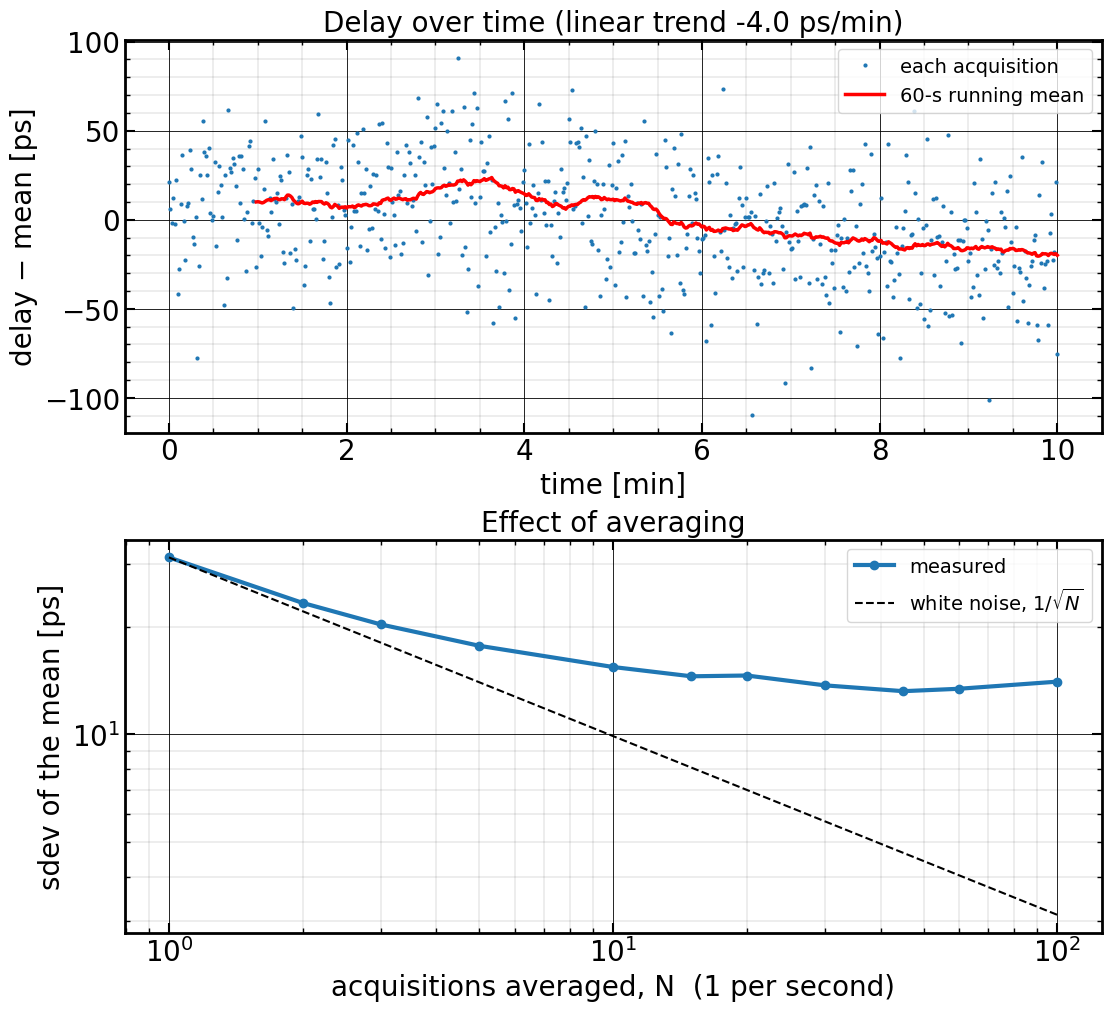

N =   1:  31.3 ps
N =   2:  23.3 ps
N =   3:  20.3 ps
N =   5:  17.7 ps
N =  10:  15.4 ps
N =  15:  14.5 ps
N =  20:  14.6 ps
N =  30:  13.7 ps
N =  45:  13.2 ps
N =  60:  13.4 ps
N = 100:  14.0 ps
first minute mean − last minute mean: +29.9 ps
lag-1 autocorrelation: 0.13


In [7]:
win = 60
run_mean = np.convolve(dev_ps, np.ones(win) / win, mode="valid")
slope_ps_per_min = np.polyfit(t_s, d, 1)[0] * 1e3 * 60

Ns = np.array([1, 2, 3, 5, 10, 15, 20, 30, 45, 60, 100])
sd_N = []
for n in Ns:
    m = d.size // n
    sd_N.append(d[: m * n].reshape(m, n).mean(axis=1).std(ddof=1) * 1e3)
sd_N = np.array(sd_N)

fig, ax = plt.subplots(2, 1, figsize=(11, 10), layout='constrained')
ax[0].plot(t_s / 60, dev_ps, ".", ms=4, color="tab:blue", label="each acquisition")
ax[0].plot(t_s[win - 1:] / 60, run_mean, "r-", lw=2.5, label=f"{win}-s running mean")
ax[0].set_xlabel("time [min]"); ax[0].set_ylabel("delay − mean [ps]")
ax[0].set_title(f"Delay over time (linear trend {slope_ps_per_min:+.1f} ps/min)", fontsize=20)
ax[0].legend(fontsize=14, loc="upper right")
ax[1].loglog(Ns, sd_N, "o-", color="tab:blue", label="measured")
ax[1].loglog(Ns, sd_N[0] / np.sqrt(Ns), "k--", lw=1.5, label="white noise, $1/\\sqrt{N}$")
ax[1].set_xlabel("acquisitions averaged, N  (1 per second)"); ax[1].set_ylabel("sdev of the mean [ps]")
ax[1].set_title("Effect of averaging", fontsize=20)
ax[1].legend(fontsize=14)
for a in ax: grids(a)
fig.savefig(RUN / "over_time.png", dpi=150)
plt.show()

for n, s in zip(Ns, sd_N):
    print(f"N = {n:3d}: {s:5.1f} ps")
print(f"first minute mean − last minute mean: {(d[:60].mean() - d[-60:].mean()) * 1e3:+.1f} ps")
print(f"lag-1 autocorrelation: {np.corrcoef(d[:-1], d[1:])[0, 1]:.2f}")

## 5. Where does the jitter come from?

The scope times both edges against its own trigger point. The PPS edge moves against the trigger by the scope's trigger jitter; the burst edge moves by that plus the jitter between EPG1 outputs 2 and 4, the board, and the noise on the slower DAC edge. The delay is their difference, so the trigger jitter cancels.

In [8]:
tp, tb = r["t_pps_ps"], r["t_burst_ps"]
print(f"PPS edge vs scope trigger   sdev {tp.std(ddof=1):5.1f} ps")
print(f"burst edge vs scope trigger sdev {tb.std(ddof=1):5.1f} ps")
print(f"delay (difference)          sdev {d.std(ddof=1) * 1e3:5.1f} ps")
print(f"correlation of the two edges: {np.corrcoef(tp, tb)[0, 1]:.2f}")

PPS edge vs scope trigger   sdev  27.4 ps
burst edge vs scope trigger sdev  42.0 ps
delay (difference)          sdev  31.3 ps
correlation of the two edges: 0.67


## 6. The waveforms

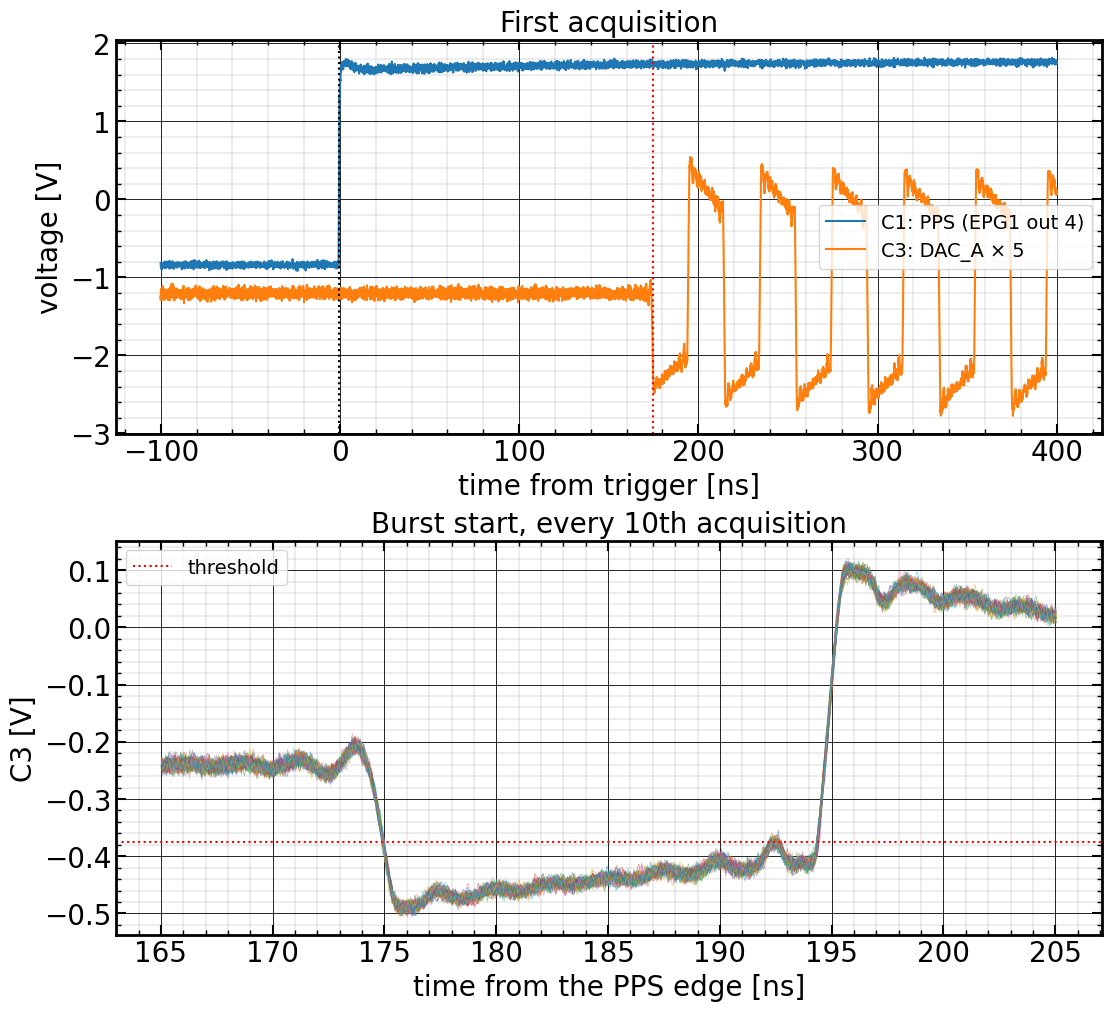

In [9]:
z = np.load(RUN / "traces.npz")
dt = float(z["dt"]); npts = z["pps"].shape[1]
t1 = z["pps_t0"][:, None] + dt * np.arange(npts)
t3 = z["dac_t0"][:, None] + dt * np.arange(npts)
tp_s, tb_s = tp * 1e-12, tb * 1e-12
base = np.median(z["dac"][0][: max(npts // 50, 10)])

fig, ax = plt.subplots(2, 1, figsize=(11, 10), layout='constrained')
ax[0].plot(t1[0] * 1e9, z["pps"][0], lw=1.5, label="C1: PPS (EPG1 out 4)")
ax[0].plot(t3[0] * 1e9, z["dac"][0] * 5, lw=1.5, label="C3: DAC_A × 5")
ax[0].axvline(tp_s[0] * 1e9, color="k", ls=":", lw=1.5)
ax[0].axvline(tb_s[0] * 1e9, color="r", ls=":", lw=1.5)
ax[0].set_xlabel("time from trigger [ns]"); ax[0].set_ylabel("voltage [V]")
ax[0].set_title("First acquisition", fontsize=20); ax[0].legend(fontsize=14, loc="center right")
m = (t3[0] > tb_s[0] - 10e-9) & (t3[0] < tb_s[0] + 30e-9)
for i in range(0, z["dac"].shape[0], 10):
    ax[1].plot((t3[i] - tp_s[i])[m] * 1e9, z["dac"][i][m], lw=0.6, alpha=0.5)
ax[1].axhline(base - 0.5 * np.percentile(np.abs(z["dac"][0] - base), 90), color="r", ls=":", lw=1.5, label="threshold")
ax[1].set_xlabel("time from the PPS edge [ns]"); ax[1].set_ylabel("C3 [V]")
ax[1].set_title("Burst start, every 10th acquisition", fontsize=20); ax[1].legend(fontsize=14)
for a in ax: grids(a)
fig.savefig(RUN / "waveforms.png", dpi=150)
plt.show()

Screenshot of the scope at the first acquisition (saved by the capture script):

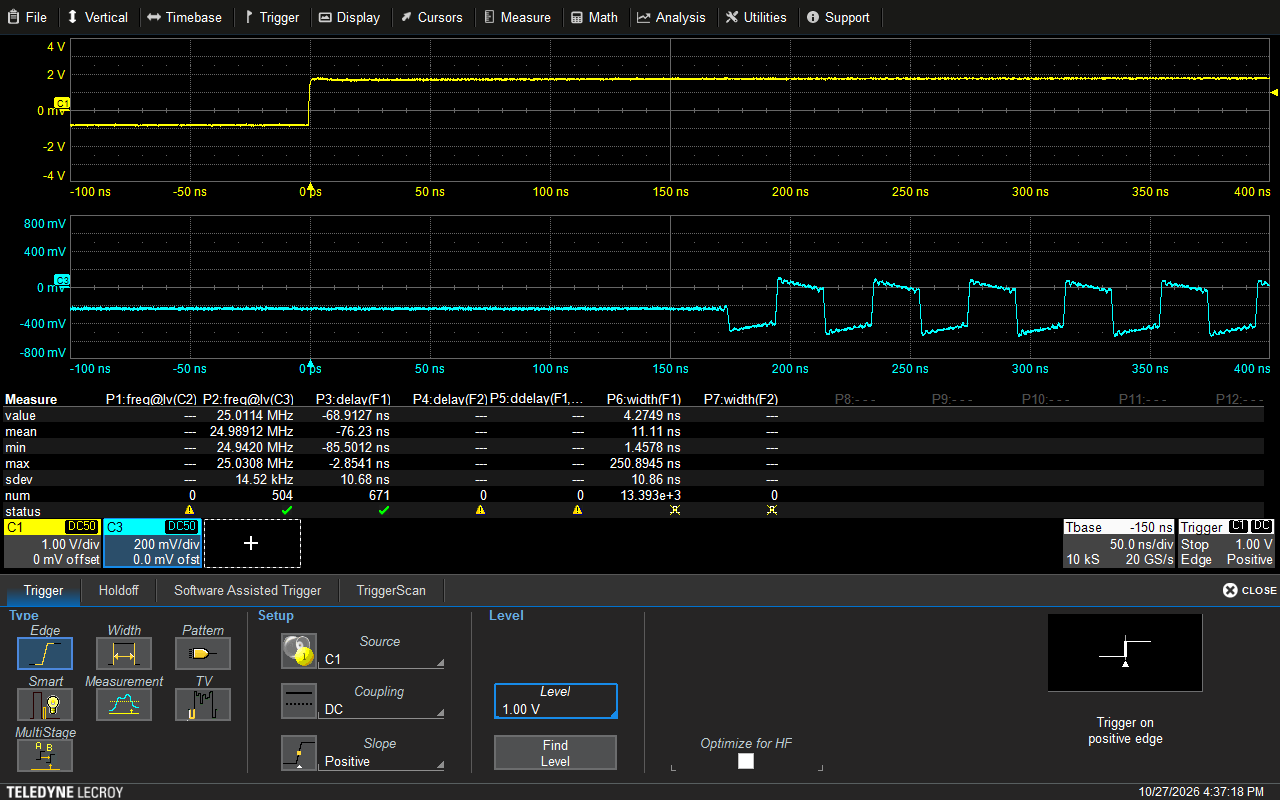

In [10]:
display(Image(filename=str(RUN / "screenshot_first.png"), width=900))

## 7. Comparison with the 2-minute run earlier the same day

In [11]:
s = load(SHORT)["delay_ns"]
print(f"2-min run  (16:20): {s.size:3d} acquisitions, mean {s.mean():.4f} ns, sdev {s.std(ddof=1) * 1e3:.1f} ps")
print(f"10-min run (16:31): {d.size:3d} acquisitions, mean {d.mean():.4f} ns, sdev {d.std(ddof=1) * 1e3:.1f} ps")
print(f"difference of the means: {(d.mean() - s.mean()) * 1e3:+.1f} ps")

2-min run  (16:20): 121 acquisitions, mean 174.9357 ns, sdev 27.0 ps
10-min run (16:31): 601 acquisitions, mean 174.9337 ns, sdev 31.3 ps
difference of the means: -2.0 ps


## 8. Summary

* **PPS → DAC_A burst start: 174.934 ns, standard deviation 31.3 ps** over 601 acquisitions (one per second, 10 min). No outliers and no jumps: the full range is 201 ps, and there are no 2.5 ns (EPG1 retiming) or 10 ns (missed tick) steps.
* The distribution is Gaussian (Shapiro-Wilk p = 0.57; skewness and kurtosis near 0).
* Most of the spread is white, second-to-second noise (lag-1 autocorrelation 0.13). Averaging 10 acquisitions brings it to about 15 ps, but averaging further gains little (13 ps at N = 60), because the delay also **drifts slowly, about −4 ps/min** (−30 ps from the first to the last minute). The cause is not identified yet; temperature changes in cables, the EPG1 or the board are candidates.
* This is the **jitter of the whole chain**, not only the board: the two EPG1 outputs (2 to the board, 4 to the scope) and the noise on the DAC edge are included. So 31 ps is an upper bound on the board's own PPS → DAC jitter (Haoyu measured 19–21 ps on his boards with the same scope).
* **The absolute value is not the board's internal delay.** It includes about 6.96 ns of EPG1 output-delay difference (output 2 7.48 ns vs output 4 0.52 ns), any cable-length difference between J7 and C1, and the scope-mode DAC data path (mixer bypassed; the 5.8 GHz configuration uses a different path).
* The mean agrees with the 2-minute run 11 minutes earlier to within a few ps, which is consistent with the drift above.

Data: `rf_clock_board/scope/scope_delay_20261027_163100/` (traces, per-acquisition delays, summary, scope screenshot, and the figures saved by this notebook).